In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
FIG, TAB, PRED = ROOT/"results"/"figures", ROOT/"results"/"tables", ROOT/"results"/"predictions"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
def savefig(name):
    plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); print("saved ->", f"results/figures/{name}.png")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")

# 09 · Deep sequence models: LSTM and GRU on the 16-week rainfall sequence

Architectures (`src/sequence_models.py`, specification in `docs/sequence_models_architecture.md`): a 2-layer LSTM or GRU encodes
$w_{-16}\to w_{-1}$; its final hidden state is concatenated with the static spatial vector (state one-hot + `IMD_Tmax`) and passed to an MLP head.
Training details (`src/sequence_experiment.py`): log1p-rainfall, training-year standardisation, standardised targets, AdamW (lr 1e-3, wd 1e-4),
gradient clipping 5.0, **early stopping on validation MAE only**, 60 epochs max, patience 10.

For every formulation tier we run three conditions with *identical architecture and static inputs*:

| condition | sequence input | what it tells us |
|---|---|---|
| `true_order` | the real 16 weekly rainfalls | the proposed model |
| `shuffled_weeks` | same values, random order inside each sample | does the **temporal ordering** matter to the recurrent network? |
| `no_weather` | zeros | how much of the performance is the weather at all (state + temperature + baseline only)? |

5 seeds for `true_order`, 3 seeds for the controls.

In [2]:
from src.experiment import *
Q = pd.read_csv(TAB/"p3_sequence_metrics.csv"); H = pd.read_csv(TAB/"p3_sequence_history.csv"); SP = pd.read_csv(PRED/"p3_sequence_test_predictions.csv.gz")
Mt = pd.read_csv(TAB/"p2_main_summary_test.csv")
D = pd.read_csv(ROOT/"data/processed/phase2_lag_features.csv.gz"); parts = split_frame(D)
print(Q[Q.split == "test"].groupby(["tier", "condition", "model"]).seed.nunique().unstack().to_string())

model                          GRU  LSTM
tier           condition                
A_weather_only no_weather        3     3
               shuffled_weeks    3     3
               true_order        5     5
C_anomaly      no_weather        3     3
               shuffled_weeks    3     3
               true_order        5     5


## 1 · Learning curves (true order, tier C)

saved -> results/figures/p2_09_learning_curves.png


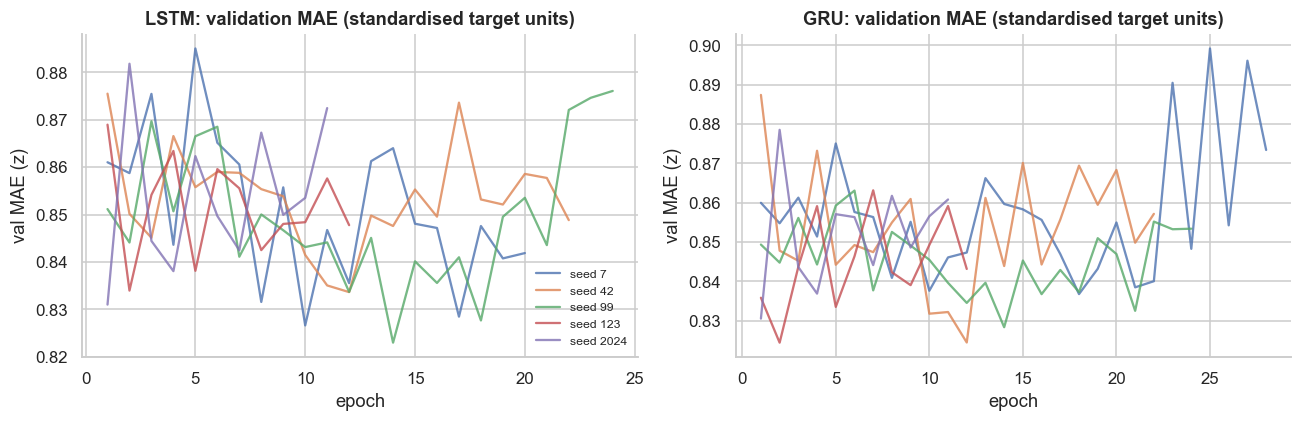

       mean epochs  min  max
model                       
GRU         19.400   11   28
LSTM        17.800   11   24


In [3]:
h = H[(H.tier == "C_anomaly") & (H.condition == "true_order")]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, arch in zip(axs, ["LSTM", "GRU"]):
    for seed, g in h[h.model == arch].groupby("seed"):
        ax.plot(g.epoch, g.val_mae * 1, alpha=.8, label=f"seed {seed}")
    ax.set_title(f"{arch}: validation MAE (standardised target units)"); ax.set_xlabel("epoch"); ax.set_ylabel("val MAE (z)")
axs[0].legend(frameon=False, fontsize=8); plt.tight_layout(); savefig("p2_09_learning_curves"); plt.show()
print(h.groupby(["model", "seed"]).epoch.max().groupby("model").agg(["mean", "min", "max"]).rename(columns={"mean": "mean epochs", "min": "min", "max": "max"}))

## 2 · Test performance by condition

In [4]:
T = Q[Q.split == "test"]
S = T.groupby(["tier", "condition", "model"]).agg(MAE=("MAE", "mean"), MAE_sd=("MAE", "std"), RMSE=("RMSE", "mean"), R2=("R2", "mean"), n=("seed", "nunique")).reset_index()
S.to_csv(TAB/"p3_sequence_summary_test.csv", index=False); S.round(3)

,tier,condition,model,MAE,MAE_sd,RMSE,R2,n
0,A_weather_only,no_weather,GRU,710.175,12.847,894.836,0.169,3
1,A_weather_only,no_weather,LSTM,712.899,9.702,897.299,0.165,3
2,A_weather_only,shuffled_weeks,GRU,697.022,6.453,879.737,0.197,3
3,A_weather_only,shuffled_weeks,LSTM,691.895,5.383,875.115,0.206,3
4,A_weather_only,true_order,GRU,679.573,7.734,863.235,0.227,5
5,A_weather_only,true_order,LSTM,687.876,6.479,872.018,0.211,5
6,C_anomaly,no_weather,GRU,333.426,0.626,485.223,0.756,3
7,C_anomaly,no_weather,LSTM,333.056,0.644,484.921,0.756,3
8,C_anomaly,shuffled_weeks,GRU,328.255,1.123,476.690,0.764,3
9,C_anomaly,shuffled_weeks,LSTM,327.284,2.690,475.535,0.766,3


saved -> results/figures/p2_09_sequence_conditions.png


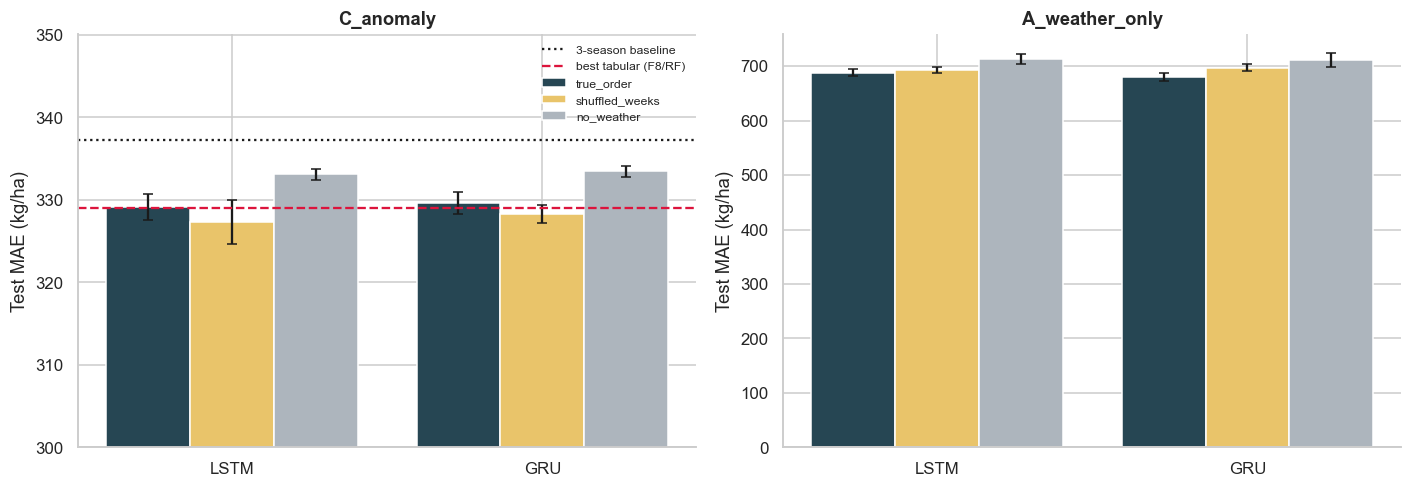

In [5]:
base_c = np.abs(parts["test"][TARGET] - parts["test"][BASE_COL]).mean()
tabC = {r.feature_set + "/" + r.model: r.MAE for r in Mt[(Mt.tier == "C_anomaly") & Mt.model.isin(["RF", "XGB", "Ridge"]) & Mt.feature_set.isin(["F1_Aggregate_IMDgrid", "F5_Lag16", "F8_Total_Anomaly", "F7_Lag16_Anomaly"])].itertuples()}
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
cols = {"true_order": "#264653", "shuffled_weeks": "#e9c46a", "no_weather": "#adb5bd"}
for ax, tier in zip(axs, ["C_anomaly", "A_weather_only"]):
    s = S[S.tier == tier]
    for k, c in enumerate(["true_order", "shuffled_weeks", "no_weather"]):
        q = s[s.condition == c].set_index("model").reindex(["LSTM", "GRU"])
        ax.bar(np.arange(2) + (k - 1) * .27, q.MAE, .27, yerr=q.MAE_sd.fillna(0), color=cols[c], label=c, capsize=3)
    if tier == "C_anomaly":
        ax.axhline(base_c, color="k", ls=":", label="3-season baseline"); ax.axhline(tabC["F8_Total_Anomaly/RF"], color="crimson", ls="--", label="best tabular (F8/RF)")
        ax.set_ylim(300, max(S[S.tier == tier].MAE) * 1.05)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["LSTM", "GRU"]); ax.set_ylabel("Test MAE (kg/ha)"); ax.set_title(tier)
axs[0].legend(frameon=False, fontsize=8); plt.tight_layout(); savefig("p2_09_sequence_conditions"); plt.show()

## 3 · Paired tests: does the true week order help the recurrent network?

In [6]:
rows = []
for tier in ["C_anomaly", "A_weather_only"]:
    for arch in ["LSTM", "GRU"]:
        def ens(cond):
            x = SP[(SP.tier == tier) & (SP.condition == cond) & (SP.model == arch)].groupby(["stable_geographic_id", "Year"]).agg(y=("Actual", "first"), p=("Predicted", "mean"))
            x["ae"] = (x.y - x.p).abs(); return x
        t = ens("true_order")
        for other in ["shuffled_weeks", "no_weather"]:
            o = ens(other); idx = t.index.intersection(o.index)
            rows.append(dict(tier=tier, model=arch, true_vs=other, **paired_cluster_bootstrap(t.loc[idx, "ae"].values, o.loc[idx, "ae"].values, np.array([i[0] for i in idx]))))
PT = pd.DataFrame(rows); PT.to_csv(TAB/"p3_sequence_paired_bootstrap.csv", index=False); PT

,tier,model,true_vs,delta_mae,ci_lo,ci_hi,p_boot
0,C_anomaly,LSTM,shuffled_weeks,2.263,0.805,3.641,0.003
1,C_anomaly,LSTM,no_weather,-4.987,-7.110,-2.938,0.000
2,C_anomaly,GRU,shuffled_weeks,1.208,-0.433,2.715,0.147
3,C_anomaly,GRU,no_weather,-5.475,-7.890,-3.245,0.000
4,A_weather_only,LSTM,shuffled_weeks,-3.984,-7.929,0.005,0.051
5,A_weather_only,LSTM,no_weather,-25.783,-36.993,-15.558,0.000
6,A_weather_only,GRU,shuffled_weeks,-17.811,-23.457,-11.960,0.000
7,A_weather_only,GRU,no_weather,-31.144,-44.106,-19.159,0.000


## 4 · Sequence models vs tabular models (same split, same tier)

In [7]:
rows = []
for r in S[S.tier == "C_anomaly"].itertuples(): rows.append(dict(model=f"{r.model} ({r.condition})", MAE=r.MAE, R2=r.R2))
for r in Mt[(Mt.tier == "C_anomaly") & Mt.feature_set.isin(["F1_Aggregate_IMDgrid", "F8_Total_Anomaly", "F5_Lag16", "F7_Lag16_Anomaly"])].itertuples(): rows.append(dict(model=f"{r.model} · {r.feature_set}", MAE=r.MAE, R2=r.R2))
rows.append(dict(model="No-weather 3-season baseline", MAE=base_c, R2=calculate_metrics(parts["test"][TARGET].values, parts["test"][BASE_COL].values)["R2"]))
CMP = pd.DataFrame(rows).sort_values("MAE"); CMP.to_csv(TAB/"p3_sequence_vs_tabular_tierC.csv", index=False); CMP.round(3).head(25)

,model,MAE,R2
3,LSTM (shuffled_weeks),327.284,0.766
2,GRU (shuffled_weeks),328.255,0.764
15,RF · F8_Total_Anomaly,329.023,0.763
5,LSTM (true_order),329.138,0.763
6,RF · F1_Aggregate_IMDgrid,329.411,0.763
4,GRU (true_order),329.618,0.762
16,Ridge · F8_Total_Anomaly,331.137,0.759
13,Ridge · F7_Lag16_Anomaly,332.225,0.758
12,RF · F7_Lag16_Anomaly,332.524,0.761
7,Ridge · F1_Aggregate_IMDgrid,332.582,0.757


### Take-aways of notebook 09
Read the paired-bootstrap table: a recurrent network that truly exploits *timing* must beat both its own shuffled-week and no-weather versions.
Differences versus the tabular models are reported alongside so the deep-learning claim of the proposal is evaluated against its strongest simple competitor.